In [ ]:
!wget  https://raw.githubusercontent.com/Rstam59/TaskDataRepoForStudents/refs/heads/main/housing.csv

--2026-01-09 06:29:40--  https://raw.githubusercontent.com/Rstam59/TaskDataRepoForStudents/refs/heads/main/housing.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1423529 (1.4M) [text/plain]
Saving to: ‘housing.csv’

housing.csv         100%[===================>]   1.36M  --.-KB/s    in 0.03s   

2026-01-09 06:29:40 (44.0 MB/s) - ‘housing.csv’ saved [1423529/1423529]



In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris(as_frame=True)
X = iris.data[["petal length (cm)", "petal width (cm)"]].values
y = (iris.target == 0) # Iris setosa

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3,  1]]
y_pred = per_clf.predict(X_new)

In [ ]:
y_pred

array([ True, False])

# Perceptron is equivalent to a SGD Classifier with loss='perceptron', no regualrization, and a constant learning rate equal to 1

In [ ]:
from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(loss='perceptron', penalty=None,
                        learning_rate='constant', eta0=1, random_state=42)

sgd_clf.fit(X, y)
assert (sgd_clf.coef_ == per_clf.coef_).all()
assert (sgd_clf.intercept_ == per_clf.intercept_).all()

# Regression MLPs

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

mlp_reg = MLPRegressor(hidden_layer_sizes=[50, 50, 50], random_state=42)
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_valid)
rmse = root_mean_squared_error(y_valid, y_pred)

In [ ]:
rmse

0.5053326657968684

Classification MLP's

In [ ]:
from sklearn.datasets import load_iris
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split

iris = load_iris()
X_train_full, X_test , y_train_full, y_test = train_test_split(iris.data,iris.target,test_size=0.1,random_state=42)
X_train,X_valid,y_train,y_valid = train_test_split(X_train_full,y_train_full,test_size=0.1,random_state=42)

mlp_clf =MLPClassifier(hidden_layer_sizes=[5],max_iter=10_000,random_state=42)

pipeline=make_pipeline(StandardScaler(),mlp_clf)
pipeline.fit(X_train,y_train)
accuracy = pipeline.score(X_valid,y_valid)
accuracy


1.0

# implementing MLPs with keras

In [ ]:
import tensorflow as tf

fashion_mnist = tf.keras.datasets.fashion_mnist.load_data()
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist
(X_train, y_train),(X_test,y_test) = fashion_mnist
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
X_train.shape

(55000, 28, 28)

In [ ]:
X_train.dtype

dtype('uint8')

In [ ]:
X_train,X_valid,X_test = X_train/255,X_valid/255,X_test/255

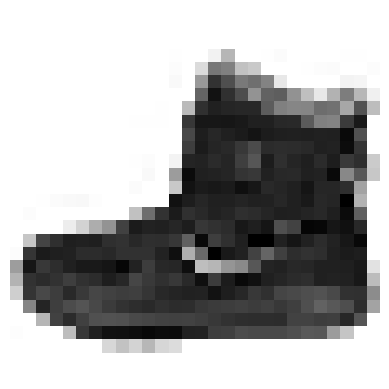

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(X_train[0],cmap='binary')
plt.axis('off')
plt.show()

In [ ]:
class_names = ["T-shirt/top","Trousers","Pullover","Dress","Coat","Sandal","Shirt","Sneaker","Bag","Ankle boot"]

In [ ]:
class_names[y_train[0]]

'Ankle boot'

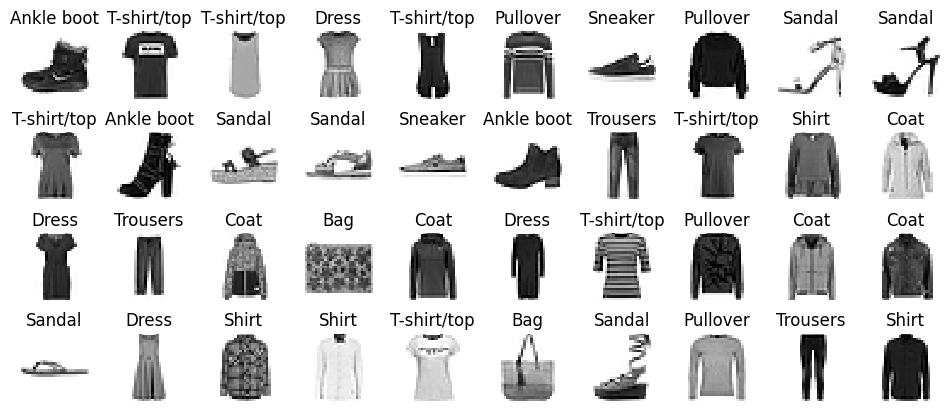

In [ ]:
n_rows=4
n_cols = 10
plt.figure(figsize=(n_cols*1.2,n_rows*1.2))
for row in range(n_rows):
  for col in range(n_cols):
    index = n_cols*row+col
    plt.subplot(n_rows,n_cols,index+1)
    plt.imshow(X_train[index],cmap='binary',interpolation='nearest')
    plt.axis('off')
    plt.title(class_names[y_train[index]],fontsize=12)
  plt.subplots_adjust(wspace=0.2,hspace=0.5)
plt.show()

In [ ]:
tf.random.set_seed(42)
model = tf.keras.Sequential()
model.add(tf.keras.layers.InputLayer(input_shape=[28,28]))
model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(300,activation='relu'))
model.add(tf.keras.layers.Dense(100,activation='relu'))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

model = tf.keras.Sequential(
    [
        tf.keras.layers.Flatten(input_shape=[28,28]),
        tf.keras.layers.Dense(300,activation='relu'),
        tf.keras.layers.Dense(100,activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

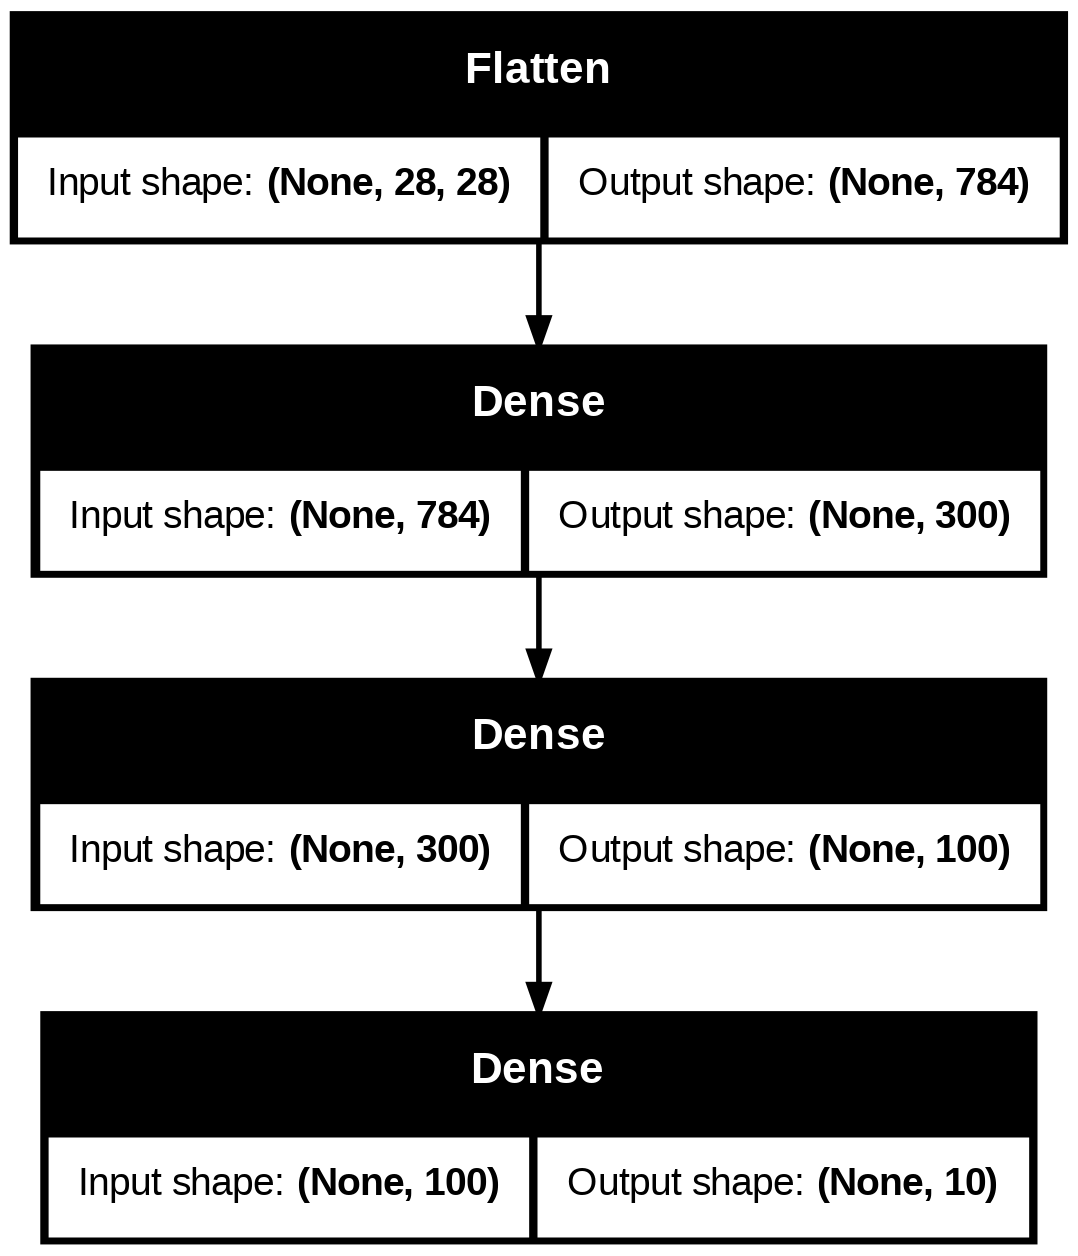

In [ ]:
tf.keras.utils.plot_model(model, "my_fashion_mnist_model.png",show_shapes=True)

In [ ]:
model.layers

[<Flatten name=flatten, built=True>,
 <Dense name=dense, built=True>,
 <Dense name=dense_1, built=True>,
 <Dense name=dense_2, built=True>]

In [ ]:
hidden1 = model.layers[1]
hidden1.name

'dense'

In [ ]:
model.get_layer('dense') is hidden1

True

In [ ]:
weights, biases = hidden1.get_weights()
weights

array([[ 0.06331557,  0.00360347, -0.03209947, ...,  0.03055064,
        -0.0238911 , -0.07191081],
       [ 0.01684048, -0.04864966,  0.01155797, ...,  0.07352947,
         0.01766264, -0.0200263 ],
       [ 0.01696855, -0.06278049,  0.01562165, ..., -0.03149645,
         0.00014554,  0.05951889],
       ...,
       [ 0.0249962 ,  0.01508147, -0.00990063, ...,  0.03422727,
         0.00205147,  0.05631921],
       [ 0.06540367,  0.03269943, -0.01830247, ..., -0.0099932 ,
         0.06345172,  0.01029906],
       [-0.04858625, -0.02392593,  0.04838427, ...,  0.04817122,
         0.05702814,  0.04351749]], dtype=float32)

In [ ]:
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

In [ ]:
weights.shape

(784, 300)

In [ ]:
biases.shape

(300,)

# Compiling the model

In [ ]:
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='sgd',
              metrics=['accuracy'])

In [ ]:
model.compile(loss=tf.keras.losses.sparse_categorical_crossentropy,
              optimizer=tf.keras.optimizers.SGD(),
              metrics=[tf.keras.metrics.sparse_categorical_accuracy])

In [ ]:
tf.keras.utils.to_categorical([0,5,1,0],num_classes=10)

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [ ]:
np.argmax([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]],axis=1)

array([0, 5, 1, 0])

# training and evaluating the model

In [ ]:
history = model.fit(X_train,y_train,epochs=30,validation_data=(X_valid,y_valid))

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.9869 - sparse_categorical_accuracy: 0.6837 - val_loss: 0.5088 - val_sparse_categorical_accuracy: 0.8286
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.5103 - sparse_categorical_accuracy: 0.8243 - val_loss: 0.4539 - val_sparse_categorical_accuracy: 0.8382
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.4557 - sparse_categorical_accuracy: 0.8419 - val_loss: 0.4309 - val_sparse_categorical_accuracy: 0.8482
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.4248 - sparse_categorical_accuracy: 0.8519 - val_loss: 0.4151 - val_sparse_categorical_accuracy: 0.8510
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - loss: 0.4023 - sparse_categorical_accuracy: 0.8595 - val_loss: 0.4062 - val_sparse_categorical_accuracy: 0.8558
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.3842 - sparse_categorical_accuracy: 0.8654 - val_loss: 0.3997 - val_sparse_categorical_accuracy:

In [ ]:
history.params

{'verbose': 'auto', 'epochs': 30, 'steps': 1719}

In [ ]:
print(history.epoch)

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


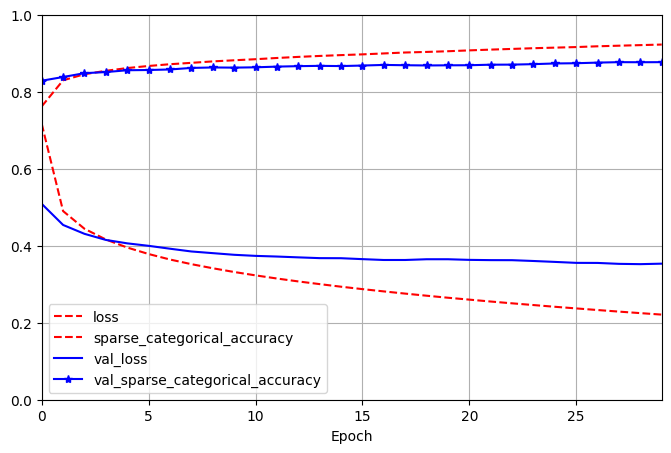

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pd.DataFrame(history.history).plot(figsize=(8,5), xlim=[0,29],ylim=[0,1],grid=True,xlabel='Epoch',style=["r--","r--","b-","b-*"])

plt.legend(loc="lower left")
plt.show()

In [ ]:
history.history

{'loss': [0.7163931131362915,
  0.48994505405426025,
  0.4440462291240692,
  0.4161481559276581,
  0.39525148272514343,
  0.3784421980381012,
  0.3641716241836548,
  0.3521190583705902,
  0.34148773550987244,
  0.33177587389945984,
  0.32299119234085083,
  0.3148435652256012,
  0.3072528541088104,
  0.3002806007862091,
  0.2935546040534973,
  0.287289559841156,
  0.28134599328041077,
  0.2756279408931732,
  0.27017706632614136,
  0.26490476727485657,
  0.2599940299987793,
  0.25505533814430237,
  0.25038349628448486,
  0.2459057867527008,
  0.24140861630439758,
  0.23717832565307617,
  0.23297430574893951,
  0.22886568307876587,
  0.22492431104183197,
  0.22108684480190277],
 'sparse_categorical_accuracy': [0.7619818449020386,
  0.8296909332275391,
  0.8454727530479431,
  0.8543272614479065,
  0.8614545464515686,
  0.8668727278709412,
  0.8714545369148254,
  0.8750181794166565,
  0.8787636160850525,
  0.881672739982605,
  0.8844545483589172,
  0.8876363635063171,
  0.8904545307159424,


In [ ]:
model.evaluate(X_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3663 - sparse_categorical_accuracy: 0.8736


[0.3644869923591614, 0.8758000135421753]

In [ ]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step


array([[0.  , 0.  , 0.  , 0.  , 0.  , 0.08, 0.  , 0.01, 0.  , 0.91],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ],
       [0.  , 1.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      dtype=float32)

In [ ]:
y_pred = y_proba.argmax(axis=-1)
y_pred

array([9, 2, 1])

In [ ]:
y_new = y_test[:3]
y_new

array([9, 2, 1], dtype=uint8)

In [ ]:
np.array(class_names)[y_pred]

array(['Ankle boot', 'Pullover', 'Trousers'], dtype='<U11')

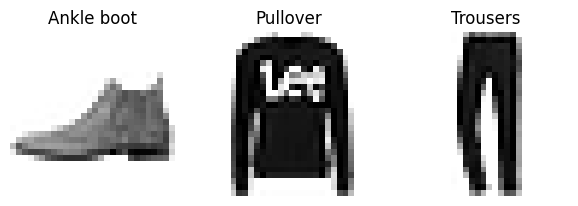

In [ ]:
plt.figure(figsize=(7.2,2.4))
for index, image in enumerate(X_new):
  plt.subplot(1,3,index+1)
  plt.imshow(image,cmap='binary',interpolation='nearest')
  plt.axis('off')
  plt.title(class_names[y_test[index]])
plt.subplots_adjust(wspace=0.2,hspace=0.5)
plt.show()

In [ ]:
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

In [ ]:
df = pd.read_csv('housing.csv')
df.drop(['ocean_proximity'], axis=1, inplace=True)
df['total_bedrooms'].fillna(df['total_bedrooms'].median(), inplace=True)
X=df.drop('median_house_value',axis=1)
y=df['median_house_value'].copy()


X_train_full, X_test, y_train_full, y_test = train_test_split(
   X,y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full, random_state=42)

/tmp/ipython-input-1085301671.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['total_bedrooms'].fillna(df['total_bedrooms'].median(), inplace=True)


In [ ]:
import tensorflow as tf
import numpy as np
tf.random.set_seed(42)
norm_layer = tf.keras.layers.Normalization(input_shape=X_train.shape[1:])
model = tf.keras.Sequential([
    norm_layer,
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1)
])
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss='mse', optimizer=optimizer, metrics=['RootMeanSquaredError'])
norm_layer.adapt(X_train.to_numpy().astype("float32"))
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))
mse_test, rmse_test = model.evaluate(X_test, y_test)
X_new = X_test[:3]
y_pred = model.predict(X_new)

Epoch 1/20


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - RootMeanSquaredError: 176844.6094 - loss: 32601313280.0000 - val_RootMeanSquaredError: 73645.8359 - val_loss: 5423709696.0000
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - RootMeanSquaredError: 71297.5703 - loss: 5085697024.0000 - val_RootMeanSquaredError: 67121.1016 - val_loss: 4505242112.0000
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - RootMeanSquaredError: 67034.5703 - loss: 4495577600.0000 - val_RootMeanSquaredError: 66177.7656 - val_loss: 4379496960.0000
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - RootMeanSquaredError: 66104.0391 - loss: 4371826688.0000 - val_RootMeanSquaredError: 65553.4141 - val_loss: 4297250304.0000
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - RootMeanSquaredError: 65362.4180 - loss: 4274391296.0000 - val_RootMeanSquaredError: 64953.1250 - val_loss: 4218908672.0000
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - RootMeanSquaredError: 64643.7578 - loss: 4180982784.0000 - val_Ro

In [ ]:
y_pred

array([[ 86854.03],
       [278475.94],
       [424537.1 ]], dtype=float32)

# Functional api

In [ ]:
tf.keras.backend.clear_session()
tf.random.set_seed(42)

In [ ]:
normalization_layer = tf.keras.layers.Normalization()
hidden_layer1 = tf.keras.layers.Dense(30, activation='relu')
hidden_layer2 = tf.keras.layers.Dense(30, activation='relu')
concat_layer = tf.keras.layers.Concatenate()
output_layer = tf.keras.layers.Dense(1)

input_ = tf.keras.layers.Input(shape=X_train.shape[1:])
normalized = normalization_layer(input_)
hidden1 = hidden_layer1(normalized)
hidden2 = hidden_layer2(hidden1)
concat = concat_layer([normalized, hidden2])
output = output_layer(concat)

model = tf.keras.Model(inputs=[input_], outputs=[output])

In [ ]:
normalized.shape

(None, 8)

In [ ]:
hidden2.shape

(None, 30)

In [ ]:
concat.shape

(None, 38)

In [ ]:
model.get_weights()

[array([0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32),
 array([1., 1., 1., 1., 1., 1., 1., 1.], dtype=float32),
 np.int64(0),
 array([[-0.11282426, -0.3356043 ,  0.18016663,  0.37414142, -0.14843662,
          0.1776469 ,  0.07660139,  0.22328517, -0.37380594,  0.17336908,
          0.30200836,  0.318301  , -0.18703987,  0.1509814 ,  0.07815918,
         -0.23979829, -0.37645257, -0.320641  ,  0.15952799,  0.21478966,
         -0.335129  ,  0.14818385,  0.29653105, -0.18670516, -0.3554268 ,
         -0.13287005, -0.30922   , -0.29489106,  0.04913366, -0.11537829],
        [-0.17901736,  0.11210832,  0.16916624, -0.16698945, -0.20081183,
          0.36019847,  0.22926095,  0.39580014,  0.253566  ,  0.22674814,
         -0.08670813, -0.01463246,  0.11726436,  0.2042841 , -0.08718184,
         -0.03512353,  0.3587251 , -0.30097398,  0.10835168, -0.05307448,
         -0.16748719,  0.0267432 , -0.05360764, -0.07753164,  0.05534145,
          0.37656167, -0.00791943,  0.24437866, -0.138254

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 8)         │         17 │ input_layer[0][0] │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30)        │        270 │ normalization[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 30)        │        930 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 38)        │          0 │ normalization[0]… │
│ (Concatenate)       │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         39 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,256 (4.91 KB)

 Trainable params: 1,239 (4.84 KB)

 Non-trainable params: 17 (72.00 B)

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss='mse', optimizer=optimizer, metrics=['RootMeanSquaredError'])
normalization_layer.adapt(X_train.to_numpy())
normalization_layer.adapt(X_test.to_numpy())
history = model.fit(X_train, y_train, epochs=20,
                    validation_data=(X_valid, y_valid))
mse_test = model.evaluate(X_test.to_numpy(), y_test)
y_pred = model.predict(X_new)

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - RootMeanSquaredError: 234936.0938 - loss: 55197138944.0000 - val_RootMeanSquaredError: 235782.5156 - val_loss: 55593398272.0000
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 234167.1406 - loss: 54836142080.0000 - val_RootMeanSquaredError: 233077.8125 - val_loss: 54325268480.0000
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 230531.0625 - loss: 53146386432.0000 - val_RootMeanSquaredError: 226308.9688 - val_loss: 51215749120.0000
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 222679.8281 - loss: 49588936704.0000 - val_RootMeanSquaredError: 215139.3438 - val_loss: 46284939264.0000
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 210600.8906 - loss: 44356792320.0000 - val_RootMeanSquaredError: 200407.7656 - val_loss: 40163274752.0000
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - RootMeanSquaredError: 195291.6094 - 

In [ ]:
tf.random.set_seed(42)

In [ ]:
input_wide = tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])
norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)
hidden1 = tf.keras.layers.Dense(30,activation='relu')(norm_deep)
hidden2 = tf.keras.layers.Dense(30,activation='relu')(hidden1)
concat = tf.keras.layers.concatenate([norm_wide,hidden2])
output = tf.keras.layers.Dense(1)(concat)
model = tf.keras.Model(inputs=[input_wide,input_deep],outputs=[output])

In [ ]:
optimmizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model.compile(loss='mse',optimizer=optimmizer,metrics=['RootMeanSquaredError'])

X_train_wide, X_train_deep = X_train.to_numpy()[:,:5], X_train.to_numpy()[:,2:]
X_valid_wide,X_valid_deep = X_valid.to_numpy()[:,:5], X_valid.to_numpy()[:,2:]
X_test_wide,X_test_deep = X_test.to_numpy()[:,:5], X_test.to_numpy()[:,2:]
X_new_wide, X_new_deep = X_test_wide[:3], X_test_deep[:3]

norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide,X_train_deep),y_train,epochs=20,
                    validation_data=((X_valid_wide,X_valid_deep),y_valid))
mse_test = model.evaluate((X_test_wide,X_test_deep),y_test)
y_pred = model.predict((X_new_wide,X_new_deep))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - RootMeanSquaredError: 234947.5781 - loss: 55202553856.0000 - val_RootMeanSquaredError: 235947.7188 - val_loss: 55671328768.0000
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 234535.5000 - loss: 55008903168.0000 - val_RootMeanSquaredError: 234422.2188 - val_loss: 54953775104.0000
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 232470.2812 - loss: 54044209152.0000 - val_RootMeanSquaredError: 230454.0312 - val_loss: 53109063680.0000
Epoch 4/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 227825.1250 - loss: 51906125824.0000 - val_RootMeanSquaredError: 223532.8750 - val_loss: 49966944256.0000
Epoch 5/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 220215.7344 - loss: 48497344512.0000 - val_RootMeanSquaredError: 213605.0000 - val_loss: 45627092992.0000
Epoch 6/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - RootMeanSquaredError: 209707.6875 - 

In [ ]:
input_wide=tf.keras.layers.Input(shape=[5])
input_deep = tf.keras.layers.Input(shape=[6])
norm_layer_wide = tf.keras.layers.Normalization()
norm_layer_deep = tf.keras.layers.Normalization()
norm_wide = norm_layer_wide(input_wide)
norm_deep = norm_layer_deep(input_deep)
hidden1 = tf.keras.layers.Dense(30,activation='relu')(norm_deep)
hidden2 = tf.keras.layers.Dense(30,activation='relu')(hidden1)
concat = tf.keras.layers.concatenate([norm_wide,hidden2])
output = tf.keras.layers.Dense(1,name="main_output")(concat)
aux_output = tf.keras.layers.Dense(1,name="aux_output")(hidden2)
model = tf.keras.Model(inputs=[input_wide,input_deep],outputs=[output,aux_output])

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

model.compile(
    optimizer=optimizer,
    loss={
        'main_output': 'mse',
        'aux_output': 'mse'
    },
    loss_weights={
        'main_output': 0.9,
        'aux_output': 0.1
    },
    metrics={
        'main_output': [tf.keras.metrics.RootMeanSquaredError()],
        'aux_output': [tf.keras.metrics.RootMeanSquaredError()]
    }
)


In [ ]:
norm_layer_wide.adapt(X_train_wide)
norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide,X_train_deep),(y_train,y_train),epochs=20,
                    validation_data=((X_valid_wide,X_valid_deep),(y_valid,y_valid)))

Epoch 1/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - aux_output_loss: 55201357824.0000 - aux_output_root_mean_squared_error: 234945.1094 - loss: 55197233152.0000 - main_output_loss: 55196737536.0000 - main_output_root_mean_squared_error: 234935.2969 - val_aux_output_loss: 55638945792.0000 - val_aux_output_root_mean_squared_error: 235884.8594 - val_loss: 55598796800.0000 - val_main_output_loss: 55591309312.0000 - val_main_output_root_mean_squared_error: 235783.8750
Epoch 2/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - aux_output_loss: 54938890240.0000 - aux_output_root_mean_squared_error: 234386.3750 - loss: 54867337216.0000 - main_output_loss: 54859350016.0000 - main_output_root_mean_squared_error: 234216.7188 - val_aux_output_loss: 54669930496.0000 - val_aux_output_root_mean_squared_error: 233821.8594 - val_loss: 54486491136.0000 - val_main_output_loss: 54463078400.0000 - val_main_output_root_mean_squared_error: 233379.1094
Epoch 3/20
363/363 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - aux_ou

In [ ]:
eval_results = model.evaluate((X_test_wide,X_test_deep),(y_test,y_test))
weighted_sum_of_losses,main_loss,aux_loss,main_rmse,aux_rmse = eval_results

162/162 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - aux_output_loss: 10325246976.0000 - aux_output_root_mean_squared_error: 101592.0625 - loss: 10323600384.0000 - main_output_loss: 10323349504.0000 - main_output_root_mean_squared_error: 101582.7266


In [ ]:
eval_results


[10050249728.0, 10044947456.0, 10047846400.0, 100263.3359375, 100249.5703125]

In [ ]:
y_pred_main,y_pred_aux = model.predict((X_new_wide,X_new_deep))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step


In [ ]:
y_pred_tuple=model.predict((X_new_wide,X_new_deep))
y_pred = dict(zip(model.output_names,y_pred_tuple))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step


In [ ]:
import keras
@keras.saving.register_keras_serializable()
class WideAndDeepModel(tf.keras.Model):
  def __init__(self,units=30,activation='relu',**kwargs):
    super().__init__(**kwargs)
    self.norm_layer_wide = tf.keras.layers.Normalization()
    self.norm_layer_deep = tf.keras.layers.Normalization()
    self.hidden1=tf.keras.layers.Dense(units,activation=activation)
    self.hidden2=tf.keras.layers.Dense(units,activation=activation)
    self.max_output=tf.keras.layers.Dense(1,name='main_output')
    self.aux_output=tf.keras.layers.Dense(1,name='aux_output')

  def call(self,inputs):
    input_wide,input_deep = inputs
    norm_wide=self.norm_layer_wide(input_wide)
    norm_deep = self.norm_layer_deep(input_deep)
    hidden1 =self.hidden1(norm_deep)
    hidden2 = self.hidden2(hidden1)
    concat = tf.keras.layers.concatenate([norm_wide,hidden2])
    output = self.max_output(concat)
    aux_output = self.aux_output(hidden2)
    return output, aux_output
tf.random.set_seed(42)
model = WideAndDeepModel(30,activation = 'relu',name='wide_and_deep')

In [ ]:
optimizer = tf.keras.optimizers.Adam(learning_rate = 1e-3)
model.build([(None,X_train_wide.shape[1:]),(None,X_train_deep.shape[1:])])
model.output_names = ['main_output','aux_output']
model.compile(loss={'main_output':'mse','aux_output':'mse'}, loss_weights = [0.9,0.1],optimizer=optimizer,metrics={'main_output':['RootMeanSquaredError'],'aux_output':['RootMeanSquaredError']})
model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)
history = model.fit((X_train_wide,X_train_deep),(y_train,y_train),epochs=10,
                    validation_data=((X_valid_wide,X_valid_deep),(y_valid,y_valid)))
eval_results = model.evaluate((X_test_wide,X_test_deep),(y_test,y_test))
weighted_sum_of_losses,main_loss,aux_loss,main_rmse,aux_rmse = eval_results
y_pred_main, y_pred_aux = model.predict((X_new_wide,X_new_deep))

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'wide_and_deep', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


363/363 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - aux_output_RootMeanSquaredError: 234945.6719 - aux_output_loss: 55201624064.0000 - loss: 55199600640.0000 - main_output_RootMeanSquaredError: 234940.8750 - main_output_loss: 55199363072.0000 - val_aux_output_RootMeanSquaredError: 235899.5312 - val_aux_output_loss: 55645859840.0000 - val_loss: 55629852672.0000 - val_main_output_RootMeanSquaredError: 235855.3750 - val_main_output_loss: 55625035776.0000
Epoch 2/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - aux_output_RootMeanSquaredError: 234426.0781 - aux_output_loss: 54957518848.0000 - loss: 54926344192.0000 - main_output_RootMeanSquaredError: 234352.1406 - main_output_loss: 54922842112.0000 - val_aux_output_RootMeanSquaredError: 234001.8125 - val_aux_output_loss: 54754119680.0000 - val_loss: 54675607552.0000 - val_main_output_RootMeanSquaredError: 233808.8438 - val_main_output_loss: 54663847936.0000
Epoch 3/10
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - aux_output_RootMeanSquaredError: 231857.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step


# Saving and Restoring Model

In [ ]:
import shutil
shutil.rmtree('my_keras_model', ignore_errors=True)


In [ ]:
model.save("my_keras_model.keras")

In [ ]:
from pathlib import Path
for path in sorted(Path("contemt").glob("**/*")):
  print(path)

In [ ]:
tf.random.set_seed(42)
model = WideAndDeepModel(30,activation='relu',name='my_cool_model')
model.build([(None,X_train_wide.shape[1:]),(None,X_train_deep.shape[1:])])
model.load_weights("/content/my_keras_model.keras")
model.norm_layer_wide.adapt(X_train_wide)
model.norm_layer_deep.adapt(X_train_deep)
y_pred_main,y_pred_aux = model.predict((X_new_wide,X_new_deep))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/layer.py:421: UserWarning: `build()` was called on layer 'my_cool_model', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 924ms/step
